# 06 : Random Forest Classification

## Objective
This notebook trains and evaluates a Random Forest classifier to distinguish VMO-dominant and VL-dominant EMG activity using extracted signal features.

## Workflow
1. Load the window-level feature dataset from Google Sheets.
2. Remove identifier columns and selected ratio features.
3. Encode the activity labels and separate features from labels.
4. Impute missing values and split the dataset into training and testing sets.
5. Train a Random Forest classifier with class weighting to address class imbalance.
6. Evaluate performance using accuracy, balanced accuracy, a classification report, and a confusion matrix.
7. Visualise feature importance and examine the class distribution.
8. Apply the trained model to features extracted from a user-provided raw EMG CSV.

## Output
Classification metrics, a confusion matrix, feature-importance visualisation, and an exploratory raw-EMG prediction pipeline.

## Interpretation note
The model predicts categories defined by the dataset's labels. These predictions are not clinically validated diagnoses and should not be interpreted as confirmed PFPS risk.


RESULTS
Accuracy: 0.9666666666666667
Balanced Accuracy: 0.9282650744260366

Classification Report:
               precision    recall  f1-score   support

VMO_dominant       0.91      0.87      0.89        47
 VL_dominant       0.98      0.98      0.98       253

    accuracy                           0.97       300
   macro avg       0.94      0.93      0.94       300
weighted avg       0.97      0.97      0.97       300


Confusion Matrix:

            Predicted VMO  Predicted VL
Actual VMO             41             6
Actual VL               4           249


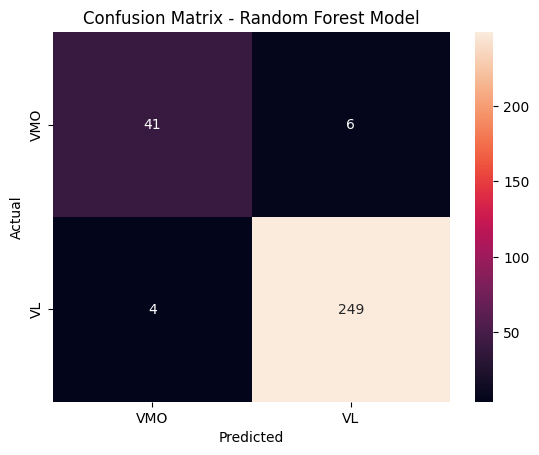

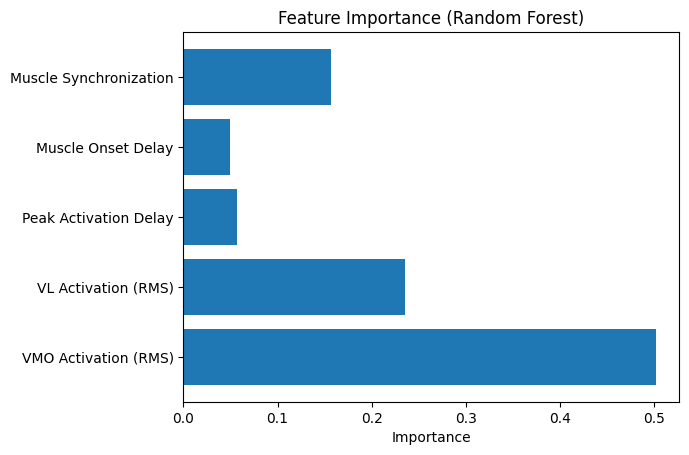


Class Distribution:
VL Dominant: 841 (84.3%)
VMO Dominant: 157 (15.7%)

Model : Random Forest Classifier

Upload CSV file (any column names allowed)


KeyboardInterrupt: 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, balanced_accuracy_score
from sklearn.impute import SimpleImputer

# -----------------------------
# 1. LOAD DATA
# -----------------------------
sheet_id = "1jpnqHp_Eaq61QzrzK0xavPfnT9xddWWyMdb5OAhd5Iw"
gid = "1292720919"

url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}"
df = pd.read_csv(url)

# -----------------------------
# 2. CLEAN DATA
# -----------------------------
df = df.drop(columns=["window_id", "start_index", "end_index"])
df = df.drop(columns=["RMS_ratio", "iEMG_ratio"])

# -----------------------------
# 3. LABELS
# -----------------------------
df["Status"] = df["Status"].str.strip().str.lower()

y = df["Status"].map({
    "vmo_dominant": 0,
    "vl_dominant": 1
})

X = df.drop(columns=["Status"])

# -----------------------------
# 4. HANDLE MISSING
# -----------------------------
imputer = SimpleImputer(strategy="mean")
X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# -----------------------------
# 5. SPLIT
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# -----------------------------
# 6. SCALE
# -----------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# -----------------------------
# 7. MODEL (IMBALANCE FIXED)
# -----------------------------
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced_subsample"
)

model.fit(X_train_scaled, y_train)

labels = ["VMO_dominant", "VL_dominant"]

# -----------------------------
# 8. EVALUATION
# -----------------------------
preds = model.predict(X_test_scaled)

print("\nRESULTS")
print("Accuracy:", accuracy_score(y_test, preds))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, preds))

print("\nClassification Report:\n",
      classification_report(y_test, preds, target_names=labels))

cm = confusion_matrix(y_test, preds)
cm_df = pd.DataFrame(cm,
                     index=["Actual VMO", "Actual VL"],
                     columns=["Predicted VMO", "Predicted VL"])

print("\nConfusion Matrix:\n")
print(cm_df)
#confusion matrix
plt.figure()
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=["VMO", "VL"],
            yticklabels=["VMO", "VL"])
plt.title("Confusion Matrix - Random Forest Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# -----------------------------
# 9. FEATURE IMPORTANCE
# -----------------------------
importances = model.feature_importances_

feature_names = [
    "VMO Activation (RMS)",
    "VL Activation (RMS)",
    "Peak Activation Delay",
    "Muscle Onset Delay",
    "Muscle Synchronization"
]

plt.figure()
plt.barh(feature_names, importances)
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance")
plt.show()

# -----------------------------
# 10. CLASS DISTRIBUTION
# -----------------------------
total = len(y)
vl_count = (y == 1).sum()
vmo_count = (y == 0).sum()

print("\nClass Distribution:")
print(f"VL Dominant: {vl_count} ({vl_count/total:.1%})")
print(f"VMO Dominant: {vmo_count} ({vmo_count/total:.1%})")

print("\nModel : Random Forest Classifier")

# ============================================================
# 🔥 11. RAW EMG PIPELINE
# ============================================================

# ---- COLAB DETECTION ----
try:
    from google.colab import files
    COLAB = True
except:
    COLAB = False

# ---- INPUT FUNCTION (ROBUST) ----
def get_user_emg():
    if COLAB:
        print("\nUpload CSV file (any column names allowed)")
        uploaded = files.upload()
        filename = list(uploaded.keys())[0]
    else:
        filename = input("Enter CSV file path: ")

    df_raw = pd.read_csv(filename)

    # Clean column names
    df_raw.columns = df_raw.columns.str.strip().str.lower()

    print("\nDetected columns:", df_raw.columns.tolist())
    print("\nPreview:\n", df_raw.head())

    # Select numeric columns
    numeric_cols = df_raw.select_dtypes(include=[np.number]).columns

    if len(numeric_cols) < 2:
        raise ValueError("CSV must contain at least 2 numeric columns")

    vmo_col = numeric_cols[0]
    vl_col  = numeric_cols[1]

    print(f"\nUsing columns → VMO: {vmo_col}, VL: {vl_col}")

    vmo = df_raw[vmo_col].values
    vl  = df_raw[vl_col].values

    return vmo, vl


# WINDOWING
def window_signal(signal, window_size=200, step=100):
    windows = []
    for i in range(0, len(signal) - window_size + 1, step):
        windows.append(signal[i:i+window_size])
    return windows


# FEATURE EXTRACTION
def extract_features(vmo_win, vl_win):
    vmo_rms = np.sqrt(np.mean(vmo_win**2))
    vl_rms  = np.sqrt(np.mean(vl_win**2))

    peak_delay = np.argmax(vl_win) - np.argmax(vmo_win)

    onset_vmo = np.argmax(vmo_win > 0.1*np.max(vmo_win))
    onset_vl  = np.argmax(vl_win > 0.1*np.max(vl_win))
    onset_delay = onset_vl - onset_vmo

    sync = np.corrcoef(vmo_win, vl_win)[0,1]

    return [vmo_rms, vl_rms, peak_delay, onset_delay, sync]


# MAIN PIPELINE
def predict_from_raw():
    vmo_signal, vl_signal = get_user_emg()

    if len(vmo_signal) < 200:
        raise ValueError("Signal too short for windowing")

    vmo_windows = window_signal(vmo_signal)
    vl_windows  = window_signal(vl_signal)

    features = []

    for vmo_w, vl_w in zip(vmo_windows, vl_windows):
        features.append(extract_features(vmo_w, vl_w))

    if len(features) == 0:
        raise ValueError("No windows generated")

    features_df = pd.DataFrame(features, columns=X.columns)

    # Apply SAME preprocessing
    features_df = pd.DataFrame(imputer.transform(features_df), columns=X.columns)
    features_scaled = scaler.transform(features_df)

    preds = model.predict(features_scaled)

    # Majority vote
    final_pred = np.bincount(preds).argmax()

    label_map = {
        0: "VMO Dominant",
        1: "VL Dominant (⚠️ Possible PFPS Risk)"
    }

    print("\nFINAL PREDICTION:", label_map[final_pred])


# -----------------------------
# RUN
# -----------------------------
predict_from_raw()
